# Modeling: LightGBM, CatBoost and CatBoost-all-categorical, plus an ensemble

Plan, building on the findings in `data_exploration.ipynb`:
1. **Re-examine missingness.** Is it really random, and can a model use it?
2. **LightGBM.** Feature ablations (raw → engineered → target-encoded exact values), then the best configuration at a lower learning rate.
3. **Class weighting.** Does up-weighting the minority class (not addicted, 29%) help?
4. **CatBoost** on numeric features, and **CatBoost with every column as a categorical feature**.
5. **Ensemble.** Compare blending methods, check what each model contributes, and decide whether to add other model families.

All data prep, features and models live in **`pipeline.py`**, which is shared with the OSCAR batch job (`oscar/`).
Every model uses the **same 5 stratified folds**. Out-of-fold (OOF) and test predictions are cached in `artifacts/`;
this notebook loads cached models and trains only the ones that are missing.
The metric is assumed to be **ROC-AUC** (binary target, probability submission).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import rankdata
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from sklearn.linear_model import LogisticRegression

import pipeline as pl   # data, folds, features, models and the artifacts/ cache
from pipeline import (train, test, y, prior, NUM, CAT, RAW, ENG, MISS, ABLATIONS, RESULTS,
                      TARGET, SEED, QUICK, train_model, paired_delta, logit)

pl.DEVICE = "cpu"   # models missing from artifacts/ are trained here; oscar/ trains them on a GPU instead
print(f"train {train.shape}, test {test.shape}, positive rate {prior:.4f}, cache {pl.ART}")

# plotting style shared with data_exploration.ipynb
C0, C1 = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#a3a29c", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.axisbelow": True,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.frameon": False, "legend.fontsize": 8, "lines.linewidth": 2,
})

train (691369, 12), test (296302, 12), positive rate 0.7094, cache /Users/pa/Documents/Kaggle Predict Phone Addiction /artifacts


## 1. Is missingness really random?

In the EDA, 9 of the 12 columns had a slightly higher addiction rate when the value was missing (by less than 0.005).
Three questions follow:
1. Is that marginal effect statistically real?
2. Is missingness related to *other* features, i.e. not completely at random (MCAR)?
3. Given all the other features, can a model actually use it? This is the question that matters for the leaderboard.

In [2]:
miss = train.isna()
rows = []
for c in train.columns:
    m = miss[c].to_numpy()
    p1, p0 = y[m].mean(), y[~m].mean()
    se = np.sqrt(prior * (1 - prior) * (1 / m.sum() + 1 / (~m).sum()))
    z = (p1 - p0) / se
    rows.append((c, m.sum(), p1 - p0, z, 2 * stats.norm.sf(abs(z))))
miss_tests = pd.DataFrame(rows, columns=["column", "n_missing", "rate_diff", "z", "p"]).set_index("column")
miss_tests["p_bonferroni"] = (miss_tests.p * len(miss_tests)).clip(upper=1)
n_missing = miss.sum(axis=1).to_numpy()
rho = stats.spearmanr(n_missing, y)
sign = stats.binomtest(int((miss_tests.rate_diff > 0).sum()), len(miss_tests))
print(f"columns with higher rate when missing: {(miss_tests.rate_diff > 0).sum()}/12 (sign test p={sign.pvalue:.3f})")
print(f"Spearman(n_missing, target) = {rho.statistic:.4f}, p = {rho.pvalue:.4f}")
miss_tests.round(4)

columns with higher rate when missing: 9/12 (sign test p=0.146)
Spearman(n_missing, target) = 0.0028, p = 0.0190


,n_missing,rate_diff,z,p,p_bonferroni
column,,,,,
age,28929,0.0042,1.5222,0.1280,1.0000
daily_screen_time_hours,95854,0.0022,1.3785,0.1681,1.0000
social_media_hours,133995,-0.0000,-0.0088,0.9930,1.0000
gaming_hours,126821,0.0013,0.9383,0.3481,1.0000
work_study_hours,51518,0.0013,0.6342,0.5259,1.0000
sleep_hours,44480,0.0042,1.8980,0.0577,0.6923
notifications_per_day,67584,0.0009,0.4929,0.6221,1.0000
app_opens_per_day,80710,0.0038,2.2385,0.0252,0.3023
weekend_screen_time,112063,0.0015,0.9903,0.3220,1.0000


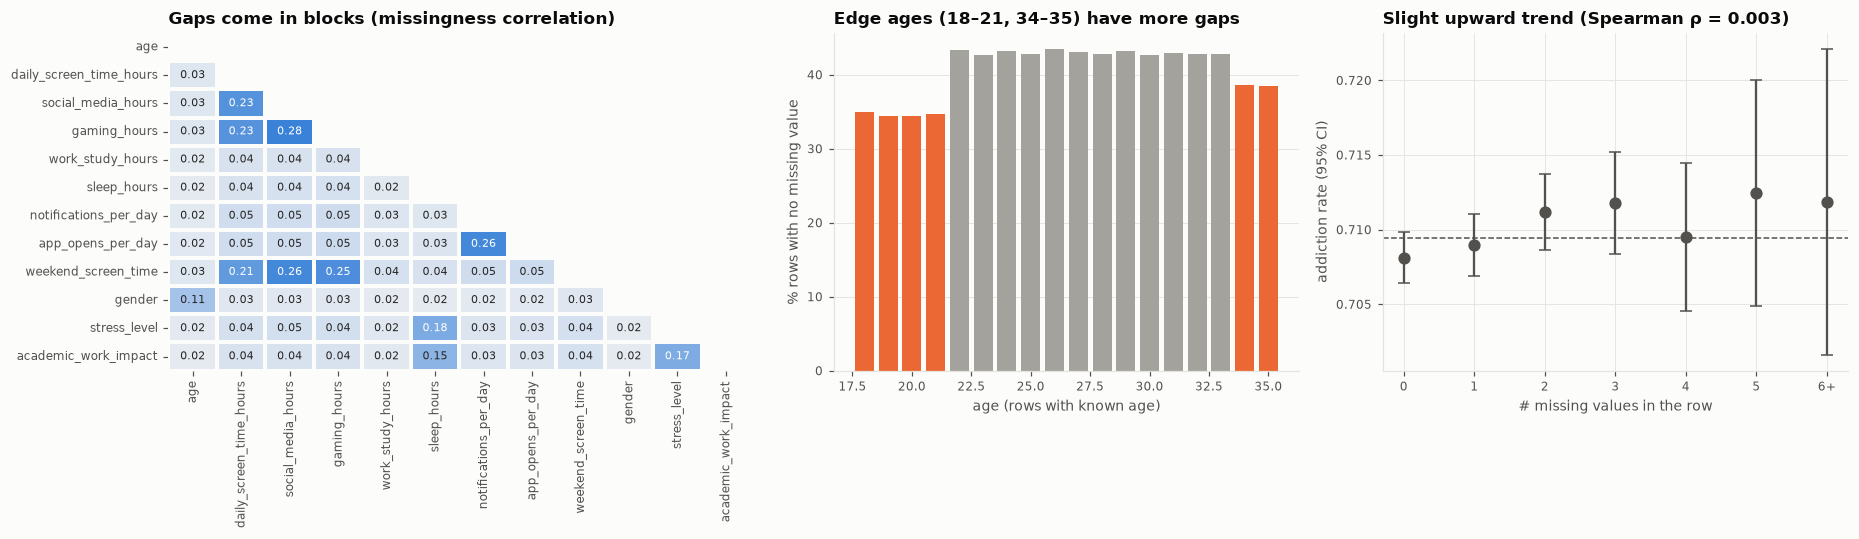

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.25, 1, 1]})

ax = axes[0]
mc = miss.astype(int).corr()
mask = np.triu(np.ones_like(mc, dtype=bool))
sns.heatmap(mc, mask=mask, cmap=sns.light_palette(C0, as_cmap=True), vmin=0, vmax=0.3, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=1.5, linecolor="#fcfcfb", cbar=False, ax=ax)
ax.set_title("Gaps come in blocks (missingness correlation)", loc="left")
ax.grid(False)

ax = axes[1]
complete_by_age = pd.Series(n_missing == 0).groupby(train["age"].to_numpy()).mean()
ax.bar(complete_by_age.index, complete_by_age.values * 100, color=[C1 if a in (18, 19, 20, 21, 34, 35) else MUTED for a in complete_by_age.index], width=0.8)
ax.set_xlabel("age (rows with known age)")
ax.set_ylabel("% rows with no missing value")
ax.set_title("Edge ages (18–21, 34–35) have more gaps", loc="left")
ax.grid(axis="x", visible=False)

ax = axes[2]
g = pd.Series(y).groupby(np.minimum(n_missing, 6)).agg(["mean", "size"])
ci = 1.96 * np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
ax.errorbar(g.index, g["mean"], yerr=ci, fmt="o", color=INK2, ms=7, capsize=4, lw=1.5)
ax.axhline(prior, color=INK2, ls="--", lw=1)
ax.set_xticks(g.index, [str(i) if i < 6 else "6+" for i in g.index])
ax.set_xlabel("# missing values in the row")
ax.set_ylabel("addiction rate (95% CI)")
ax.set_title(f"Slight upward trend (Spearman ρ = {rho.statistic:.3f})", loc="left")
plt.tight_layout(); plt.show()

**Statistical answer.** Missingness is **not completely at random**:
* Gaps co-occur in four blocks: {daily screen, weekend screen, social, gaming}, {sleep, stress, academic impact},
  {notifications, app opens} and {age, gender}.
* Rows at the edges of the age range have noticeably more gaps.
* The marginal link to the target is real but tiny. Per column it is never significant after a Bonferroni correction,
  but the pooled count of missing values per row has ρ ≈ 0.003 (p ≈ 0.01).

A correlation that small has a ceiling of about +0.002 AUC on its own. Whether it adds anything *on top of* the
other features is tested directly with LightGBM in section 2 (`lgb_best+missing`).

## 2. Features and the cross-validation harness (defined in `pipeline.py`)
* **Engineered features** (from the EDA): screen time with gaps filled from weekend time, sum of the parts,
  other hours, the social / gaming / work shares, and weekend − daily.
* **Missing features:** one indicator per column, plus `n_missing`.
* **Exact-value target encoding:** nested out-of-fold encoding inside each training fold. Training rows get
  inner-fold values, while validation and test rows use the encoding fit on the whole training fold, so there is no leakage.

In [4]:
print("engineered:", ENG)
print("missing:", MISS)
pl.X_TR[ENG].describe().T.round(3)

engineered: ['screen_filled', 'parts_sum', 'other_hours', 'social_share', 'gaming_share', 'work_share', 'weekend_minus_daily']
missing: ['miss_age', 'miss_daily_screen_time_hours', 'miss_social_media_hours', 'miss_gaming_hours', 'miss_work_study_hours', 'miss_sleep_hours', 'miss_notifications_per_day', 'miss_app_opens_per_day', 'miss_weekend_screen_time', 'miss_gender', 'miss_stress_level', 'miss_academic_work_impact', 'n_missing']


,count,mean,std,min,25%,50%,75%,max
screen_filled,656915.0,7.643,2.686,0.500,5.509,7.770,9.810,15.000
parts_sum,451825.0,6.296,2.200,0.010,4.630,6.250,7.960,14.560
other_hours,441591.0,1.341,1.498,-5.388,0.460,0.760,1.520,11.530
social_share,538143.0,0.327,0.136,0.000,0.230,0.330,0.418,2.979
gaming_share,544575.0,0.197,0.112,0.000,0.107,0.198,0.274,3.312
work_share,609407.0,0.319,0.140,0.000,0.213,0.320,0.413,3.152
weekend_minus_daily,517906.0,1.838,1.766,-7.910,0.630,1.840,3.030,11.490


## 3. LightGBM: feature ablation
The ablations run at learning rate 0.1 for speed; only the relative ranking matters here.
Every variant uses identical folds, so per-fold differences are paired.

In [5]:
for name in ABLATIONS:
    train_model(name)
best_ablation = pl.best_ablation()
print("best feature set:", best_ablation)

# on top of the best set: missing indicators, and class re-weighting
train_model("lgb_best+missing")
train_model("lgb_best+balanced")

lgb_raw: loaded from cache, OOF AUC 0.96345
lgb_eng: loaded from cache, OOF AUC 0.96427
lgb_eng_te4: loaded from cache, OOF AUC 0.96461
lgb_eng_te9: loaded from cache, OOF AUC 0.96744
best feature set: lgb_eng_te9
lgb_best+missing: loaded from cache, OOF AUC 0.96746
lgb_best+balanced: loaded from cache, OOF AUC 0.96738


{'oof': array([0.85192587, 0.03893942, 0.11077921, ..., 0.33265176, 0.98563614,
        0.14978397], shape=(691369,)),
 'test': array([0.9992705 , 0.88161643, 0.72488995, ..., 0.09470599, 0.57758861,
        0.66961485], shape=(296302,)),
 'fold_auc': array([0.96670363, 0.96747971, 0.96759978, 0.96799909, 0.96714375]),
 'iters': array([366, 427, 386, 490, 477]),
 'secs': array(184.99507499)}

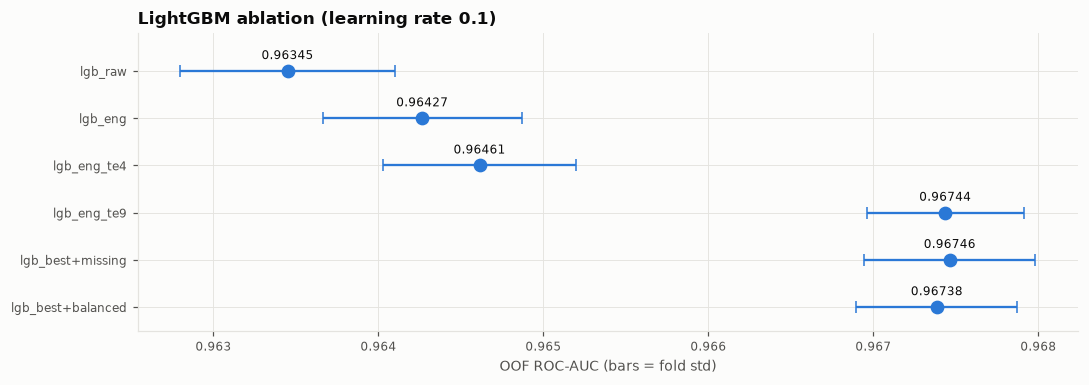

,OOF AUC,Δ vs previous / best,± SE,OOF log loss,mean iters
lgb_raw,0.96345,NaN,NaN,0.22104,787.0
lgb_eng,0.96427,0.00082,0.00003,0.21862,688.0
lgb_eng_te4,0.96461,0.00035,0.00004,0.21756,538.2
lgb_eng_te9,0.96744,0.00282,0.00006,0.20906,448.4
lgb_best+missing,0.96746,0.00002,0.00003,0.20896,388.0
lgb_best+balanced,0.96738,-0.00005,0.00002,0.23103,429.2


In [6]:
order = list(ABLATIONS) + ["lgb_best+missing", "lgb_best+balanced"]
tbl = pd.DataFrame({
    "OOF AUC": [roc_auc_score(y, RESULTS[n]["oof"]) for n in order],
    "Δ vs previous / best": [np.nan] + [paired_delta(a, b)[0] for a, b in zip(order[:3], order[1:4])]
                            + [paired_delta(best_ablation, n)[0] for n in order[4:]],
    "± SE": [np.nan] + [paired_delta(a, b)[1] for a, b in zip(order[:3], order[1:4])]
            + [paired_delta(best_ablation, n)[1] for n in order[4:]],
    "OOF log loss": [log_loss(y, RESULTS[n]["oof"]) for n in order],
    "mean iters": [RESULTS[n]["iters"].mean() for n in order],
}, index=order)

fig, ax = plt.subplots(figsize=(10, 3.6))
aucs = tbl["OOF AUC"].to_numpy()[::-1]
fold_sd = [RESULTS[n]["fold_auc"].std(ddof=1) for n in order][::-1]
ax.errorbar(aucs, order[::-1], xerr=fold_sd, fmt="o", color=C0, ms=8, capsize=4, lw=1.5)
for i, v in enumerate(aucs):
    ax.text(v, i + 0.25, f"{v:.5f}", ha="center", fontsize=8, color=INK)
ax.set_ylim(-0.5, len(order) - 0.2)
ax.set_xlabel("OOF ROC-AUC (bars = fold std)")
ax.set_title("LightGBM ablation (learning rate 0.1)", loc="left")
plt.tight_layout(); plt.show()
tbl.round(5)

## 4. Should the minority class (not addicted, 29%) be up-weighted?
`lgb_best+balanced` gives the negative class a weight of 0.71 / 0.29 ≈ 2.44, so both classes carry equal total weight.

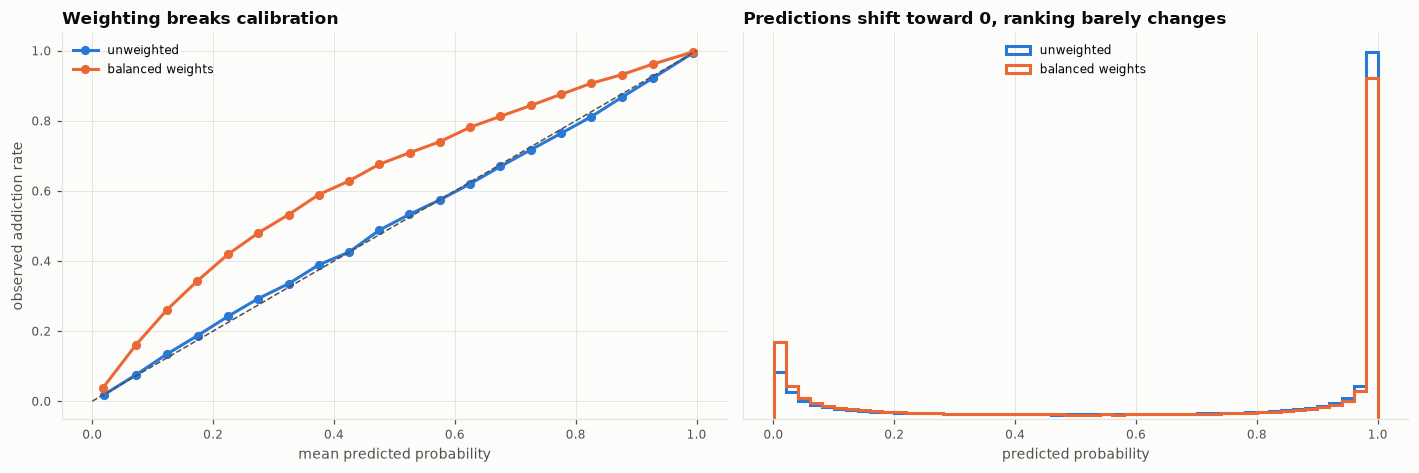

paired ΔAUC balanced − unweighted: -0.00005 ± 0.00002


,unweighted,balanced weights,unweighted + post-hoc shift
ROC-AUC,0.96744,0.96738,0.96744
log loss,0.20906,0.23103,0.23501
Brier,0.06529,0.07296,0.07408
mean prediction,0.70921,0.65728,0.65189


In [7]:
base, bal = RESULTS[best_ablation]["oof"], RESULTS["lgb_best+balanced"]["oof"]
logit = lambda p: np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))
shifted = 1 / (1 + np.exp(-(logit(base) - 0.9)))   # post-hoc shift: push every probability toward class 0
cmp = pd.DataFrame({
    "unweighted": [roc_auc_score(y, base), log_loss(y, base), brier_score_loss(y, base), base.mean()],
    "balanced weights": [roc_auc_score(y, bal), log_loss(y, bal), brier_score_loss(y, bal), bal.mean()],
    "unweighted + post-hoc shift": [roc_auc_score(y, shifted), log_loss(y, shifted), brier_score_loss(y, shifted), shifted.mean()],
}, index=["ROC-AUC", "log loss", "Brier", "mean prediction"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
bins = np.linspace(0, 1, 21)
for p, col, lab in [(base, C0, "unweighted"), (bal, C1, "balanced weights")]:
    idx = np.digitize(p, bins[1:-1])
    obs = pd.Series(y).groupby(idx).mean()
    pred = pd.Series(p).groupby(idx).mean()
    ax.plot(pred, obs, marker="o", ms=5, color=col, label=lab)
ax.plot([0, 1], [0, 1], color=INK2, ls="--", lw=1)
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed addiction rate")
ax.set_title("Weighting breaks calibration", loc="left"); ax.legend()
ax = axes[1]
ax.hist(base, bins=50, histtype="step", color=C0, lw=2, label="unweighted")
ax.hist(bal, bins=50, histtype="step", color=C1, lw=2, label="balanced weights")
ax.set_xlabel("predicted probability"); ax.set_yticks([])
ax.set_title("Predictions shift toward 0, ranking barely changes", loc="left"); ax.legend(loc="upper center")
plt.tight_layout(); plt.show()
d, se = paired_delta(best_ablation, "lgb_best+balanced")
print(f"paired ΔAUC balanced − unweighted: {d:+.5f} ± {se:.5f}")
cmp.round(5)

## 5. Final models
* **`lgb_final`**: the best LightGBM configuration at learning rate 0.03. Missing indicators are included only if section 3 showed a significant gain.
* **`cb_num`**: CatBoost on numeric + engineered features. The columns target-encoded in the best LightGBM are added as
  **categorical copies**, and CatBoost's ordered target statistics stand in for the manual target encoding.
  Only single-feature statistics are used (`max_ctr_complexity=1`): combinations are `cb_allcat`'s job, and they make this model about 4× slower.
* **`cb_allcat`**: CatBoost with **every raw column as a categorical feature** (exact values, with "nan" as its own level).
  It uses pairwise categorical combinations (`max_ctr_complexity=2`).

In [8]:
d_miss, se_miss = paired_delta(best_ablation, "lgb_best+missing")
print(f"missing indicators: Δ {d_miss:+.5f} ± {se_miss:.5f} → {'include' if pl.use_missing() else 'exclude'}")
train_model("lgb_final")

missing indicators: Δ +0.00002 ± 0.00003 → exclude
lgb_final: loaded from cache, OOF AUC 0.96797


{'oof': array([0.92086422, 0.04961094, 0.24199442, ..., 0.56174158, 0.99374091,
        0.37539185], shape=(691369,)),
 'test': array([0.99969881, 0.92822388, 0.80039859, ..., 0.16873462, 0.78734196,
        0.82194808], shape=(296302,)),
 'fold_auc': array([0.96737769, 0.96803447, 0.96821415, 0.96852307, 0.96771326]),
 'iters': array([2628, 1930, 1883, 1883, 1766]),
 'secs': array(692.10145783)}

In [9]:
# slow on a laptop CPU (1-3 h each): oscar/train_gpu.slurm trains them on a GPU, then copy the .npz files into artifacts/
train_model("cb_num")
train_model("cb_allcat")

cb_num: loaded from cache, OOF AUC 0.96735
cb_allcat: loaded from cache, OOF AUC 0.96187


{'oof': array([0.92046015, 0.07620622, 0.21764778, ..., 0.51925556, 0.98056908,
        0.2676929 ], shape=(691369,)),
 'test': array([0.99899184, 0.98624193, 0.81233225, ..., 0.18620158, 0.65116276,
        0.70040266], shape=(296302,)),
 'fold_auc': array([0.96117003, 0.96207047, 0.96221831, 0.96267997, 0.96125605]),
 'iters': array([2372, 2752, 1938, 2396, 2128]),
 'secs': array(283.18238115)}

## 6. Is a different model family worth adding?
A good ensemble member must be **accurate** and **make different errors**. As a cheap probe of a very different
family, I fit a **logistic regression** on splines of the numeric features plus target encodings of all 12 columns.
If even a model this different adds nothing to the stack, a neural net or XGBoost (another GBDT, so a near-duplicate of LightGBM)
is unlikely to justify its training cost.

In [10]:
train_model("logreg_probe")

logreg_probe: loaded from cache, OOF AUC 0.96108


{'oof': array([0.89056704, 0.05726246, 0.1740001 , ..., 0.54107617, 0.99952357,
        0.25655572], shape=(691369,)),
 'test': array([0.99953823, 0.94490007, 0.87035823, ..., 0.14583699, 0.53919953,
        0.76619651], shape=(296302,)),
 'fold_auc': array([0.96020069, 0.96105624, 0.96166979, 0.96185858, 0.96064871]),
 'iters': array([0, 0, 0, 0, 0]),
 'secs': array(185.80711818)}

## 7. Ensemble

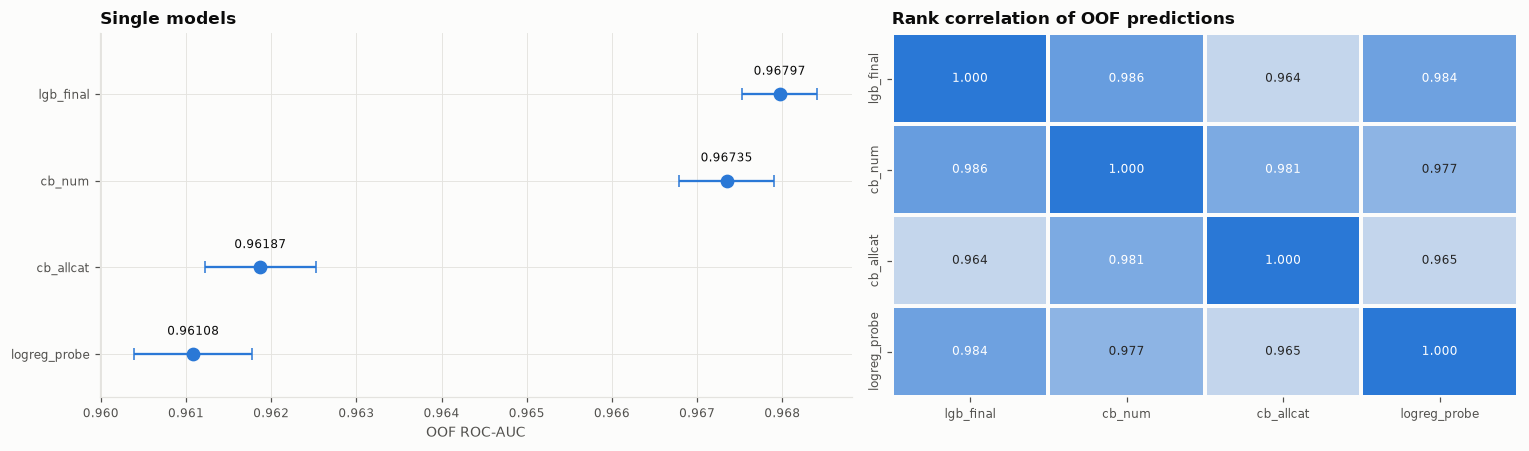

In [11]:
MODELS = ["lgb_final", "cb_num", "cb_allcat"]
CANDIDATES = MODELS + ["logreg_probe"]
P = pd.DataFrame({n: RESULTS[n]["oof"] for n in CANDIDATES})
T = pd.DataFrame({n: RESULTS[n]["test"] for n in CANDIDATES})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
single = pd.Series({n: roc_auc_score(y, P[n]) for n in CANDIDATES}).sort_values()
ax.errorbar(single.values, single.index, xerr=[RESULTS[n]["fold_auc"].std(ddof=1) for n in single.index],
            fmt="o", color=C0, ms=8, capsize=4, lw=1.5)
for i, v in enumerate(single.values):
    ax.text(v, i + 0.22, f"{v:.5f}", ha="center", fontsize=8, color=INK)
ax.set_ylim(-0.5, len(single) - 0.3)
ax.set_xlabel("OOF ROC-AUC"); ax.set_title("Single models", loc="left")
ax = axes[1]
rc = P.rank().corr()
sns.heatmap(rc, cmap=sns.light_palette(C0, as_cmap=True), vmin=rc.values.min() - 0.01, vmax=1, annot=True, fmt=".3f",
            annot_kws={"size": 8}, linewidths=1.5, linecolor="#fcfcfb", cbar=False, ax=ax)
ax.set_title("Rank correlation of OOF predictions", loc="left"); ax.grid(False)
plt.tight_layout(); plt.show()

stack weights on logits:
 lgb_final    0.642
cb_num       0.351
cb_allcat   -0.003


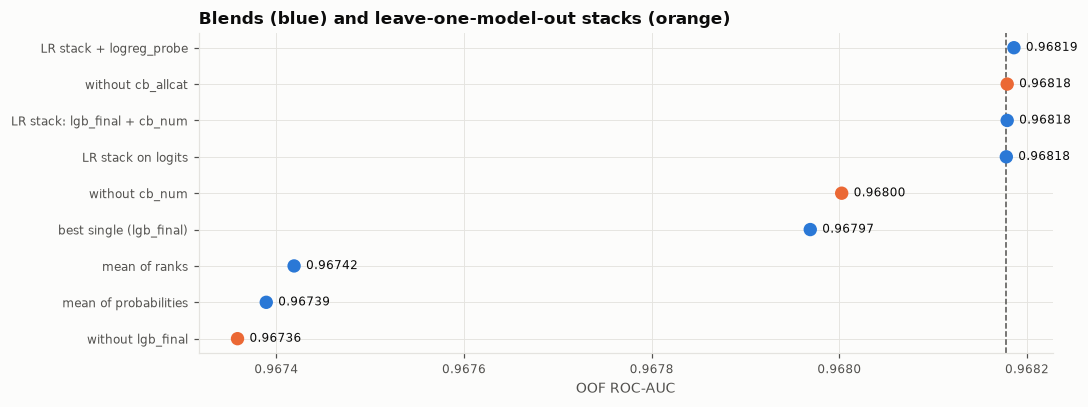

,OOF AUC
best single (lgb_final),0.96797
mean of probabilities,0.96739
mean of ranks,0.96742
LR stack: lgb_final + cb_num,0.96818
LR stack on logits,0.96818
LR stack + logreg_probe,0.96819
without lgb_final,0.96736
without cb_num,0.96800
without cb_allcat,0.96818


In [12]:
stack_cv = StratifiedKFold(5, shuffle=True, random_state=SEED + 7)   # different split from the base-model folds

def stack_oof(cols):
    """Logistic-regression stack on logits, evaluated out-of-fold on the base models' OOF predictions."""
    Z = logit(P[cols].to_numpy())
    return cross_val_predict(LogisticRegression(C=1.0), Z, y, cv=stack_cv, method="predict_proba")[:, 1]

def rank_mean(df):
    return np.mean([rankdata(df[c]) / len(df) for c in df.columns], axis=0)

blends = {
    "best single (lgb_final)": P["lgb_final"],
    "mean of probabilities": P[MODELS].mean(axis=1),
    "mean of ranks": rank_mean(P[MODELS]),
    "LR stack: lgb_final + cb_num": stack_oof(["lgb_final", "cb_num"]),
    "LR stack on logits": stack_oof(MODELS),
    "LR stack + logreg_probe": stack_oof(CANDIDATES),
}
blend_auc = pd.Series({k: roc_auc_score(y, v) for k, v in blends.items()})

# leave-one-out: what each base model contributes to the 3-model stack
loo = pd.Series({f"without {m}": roc_auc_score(y, stack_oof([n for n in MODELS if n != m])) for m in MODELS})

stack = LogisticRegression(C=1.0).fit(logit(P[MODELS].to_numpy()), y)
weights = pd.Series(stack.coef_[0], index=MODELS)
print("stack weights on logits:\n", weights.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 3.8))
allres = pd.concat([blend_auc, loo]).sort_values()
colors = [C1 if k.startswith("without") else C0 for k in allres.index]
ax.scatter(allres.values, allres.index, color=colors, s=60, zorder=3)
for i, v in enumerate(allres.values):
    ax.text(v, i, f"   {v:.5f}", va="center", fontsize=8, color=INK)
ax.axvline(blend_auc["LR stack on logits"], color=INK2, ls="--", lw=1)
ax.set_xlabel("OOF ROC-AUC"); ax.set_title("Blends (blue) and leave-one-model-out stacks (orange)", loc="left")
plt.tight_layout(); plt.show()
pd.concat([blend_auc, loo]).round(5).to_frame("OOF AUC")

In [13]:
# the simplest stack within noise (0.00005 AUC) of the best one
STACKS = {"LR stack: lgb_final + cb_num": ["lgb_final", "cb_num"], "LR stack on logits": MODELS, "LR stack + logreg_probe": CANDIDATES}
best_auc = max(blend_auc[k] for k in STACKS)
final_name = next(k for k in STACKS if blend_auc[k] >= best_auc - 5e-5)
cols = STACKS[final_name]

d = np.array([roc_auc_score(y[va], blends[final_name][va]) - roc_auc_score(y[va], P["lgb_final"].to_numpy()[va]) for _, va in pl.folds])
print(f"ensemble used: {final_name}  (OOF AUC {blend_auc[final_name]:.5f}; "
      f"Δ vs lgb_final {d.mean():+.5f} ± {d.std(ddof=1) / np.sqrt(len(d)):.5f}, positive in {(d > 0).sum()}/{len(d)} folds)")

st = LogisticRegression(C=1.0).fit(logit(P[cols].to_numpy()), y)
print("stack weights on logits:", dict(zip(cols, st.coef_[0].round(3))), " intercept", st.intercept_.round(3))
sub = pd.DataFrame({"id": test.index, TARGET: st.predict_proba(logit(T[cols].to_numpy()))[:, 1]})
if not QUICK:
    sub.to_csv("submission.csv", index=False)
sub[TARGET].describe().round(4)

ensemble used: LR stack: lgb_final + cb_num  (OOF AUC 0.96818; Δ vs lgb_final +0.00021 ± 0.00002, positive in 5/5 folds)
stack weights on logits: {'lgb_final': np.float64(0.641), 'cb_num': np.float64(0.349)}  intercept [-0.002]


count    296302.0000
mean          0.7093
std           0.3776
min           0.0002
25%           0.3606
50%           0.9627
75%           0.9996
max           1.0000
Name: addicted_label, dtype: float64

---
## 8. Conclusions

**Models (5-fold OOF ROC-AUC, identical folds)**

| model | OOF AUC | notes |
|---|---|---|
| `lgb_final` | **0.96797** | raw + engineered + nested-OOF target encoding of all 9 numeric columns, learning rate 0.03 |
| `cb_num` | 0.96735 | numeric + engineered + categorical copies of the 9 numeric columns |
| `cb_allcat` | 0.96187 | every column as a categorical feature |
| `logreg_probe` | 0.96108 | splines + target encodings (diversity probe) |
| **stack: lgb_final + cb_num** | **0.96818** | +0.00021 ± 0.00002 over `lgb_final`, positive in all 5 folds |

**1. Ensemble.** A logistic-regression stack on logits beats the best single model by a small but consistent margin.
A plain mean of probabilities or ranks is *worse* than `lgb_final` (0.96739), because the weaker `cb_allcat` drags it down.
The stack learns to give `cb_allcat` a weight of ≈ 0.

**2. Other models are not worth adding.** All the models rank rows almost identically (rank correlation 0.96–0.99).
Even the most different model family, the logistic regression, adds only +0.00001. The stack leaves `cb_allcat` out entirely.
XGBoost would be a third GBDT on the same features, and a neural net would likely behave like the logistic regression
on these mostly one-dimensional effects. Neither is likely to add anything measurable. Better places for effort:
* tune `lgb_final` and `cb_num` (num_leaves/depth, min_child_samples, regularisation, target-encoding smoothing), running on OSCAR;
* average 3–5 seeds of each model, which typically adds +0.0001 to +0.0003 at this level;
* add the original (non-synthetic) dataset this competition was generated from, if it is available. The exact-value
  signal suggests the synthetic rows are tied closely to it.

**3. Up-weighting the minority class does not help.** Balanced weights change AUC by −0.00005 ± 0.00002 and push the
mean prediction from 0.709 to 0.657, so log loss rises from 0.209 to 0.231. AUC depends only on how rows are ranked.
Re-weighting barely changes the ranking, and a post-hoc probability shift changes it not at all (identical AUC).
What weighting does change is calibration, for the worse. Only weight the classes if the metric is threshold-based
(F1, balanced accuracy); even then, it's better to keep the model unweighted and tune the decision threshold.

**4. Missingness is structured but not useful.** You were right that it isn't completely random: gaps come in blocks,
they are more common at the edge ages, and the missing count has a small but statistically real link to the target
(ρ = 0.003, p = 0.02). But given the other features, the indicators add +0.00002 ± 0.00003 AUC, i.e. nothing.
LightGBM's native NaN handling already captures what there is. They are left out of the final model.
